# Validation hors période (OOT) du score « Mono-détenus sans engagement »

Le score du segment **SA** (clients seuls titulaires de leur dossier et sans crédit) a été construit dans le notebook `Analyse_Mono_Sans_Engagement_decoupe.ipynb`, sur quatre mois d'observation. Ce notebook le teste sur une **nouvelle période** (échantillon *Out-of-Time*, cours §1.5).

Le principe est simple : **rien n'est réappris sur l'OOT**. Les seuils de découpage, les variables croisées, les coefficients, la grille de points, les bornes des CHR et les probabilités de défaut viennent tous du développement. Nous les appliquons tels quels à la nouvelle période, puis nous refaisons les analyses du notebook de développement pour voir si le score tient dans le temps.

| Partie | Ce que nous faisons |
|---|---|
| 0 | Paramètres |
| 1 | Extraction du segment SA dans la base OOT (mêmes règles que la segmentation) |
| 2 | Reconstruction du modèle de développement, à l'identique |
| 3 | Préparation de la base OOT (mêmes traitements que le train) |
| 4 | Population et cible sur l'OOT |
| 5 | Qualité et stabilité des variables |
| 6 | Pouvoir discriminant : Gini, KS, courbes ROC |
| 7 | Classes homogènes de risque (CHR) |
| 8 | Calibrage : les probabilités de défaut tiennent-elles ? |
| 9 | Synthèse et décision |

Repères utilisés pour juger la stabilité :

| Indicateur | Stable | À surveiller | Alerte |
|---|---|---|---|
| PSI (score, CHR, variables) | < 0,10 | 0,10 à 0,25 | > 0,25 |
| Baisse relative du Gini (OOT par rapport au test) | < 10 % | 10 à 20 % | > 20 % |
| Test binomial par CHR (sous-estimation de la PD) | p-value ≥ 5 % | | p-value < 5 % |

## 0. Paramètres

Les chemins peuvent être changés par des variables d'environnement, comme dans le notebook de développement. Les noms des colonnes clés sont les mêmes que dans le développement.

In [1]:
# Librairies
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
from IPython.display import display
from IPython.utils.capture import capture_output
from scipy import stats
from sklearn.metrics import roc_auc_score, roc_curve

# Nos fonctions, rangées dans le dossier utils/
from utils import binning as bn
from utils import exploration as ex
from utils import feature_engineering as fe
from utils.segmentation import construire_candidats

pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(20)

polars.config.Config

In [2]:
# Notebook de développement et base de développement du segment
NOTEBOOK_DEV = Path("Analyse_Mono_Sans_Engagement_decoupe.ipynb")
BASE_DEV = Path(os.environ.get("SCORING_BASE",
                               "data/segments/mono_sans_engagement/base_mono_sans_engagement.parquet"))

# Base OOT : fichier SAS d'origine, copie parquet, et segment SA extrait
SOURCE_OOT = Path(os.environ.get("SCORING_SOURCE_OOT", "data/_01_99__ensai_par_oot_final.sas7bdat"))
CACHE_OOT = Path(os.environ.get("SCORING_CACHE_OOT", "data/processed/base_oot.parquet"))
BASE_OOT = Path(os.environ.get("SCORING_BASE_OOT",
                               "data/segments/mono_sans_engagement/base_mono_sans_engagement_oot.parquet"))
SORTIES_OOT = Path(os.environ.get("SCORING_SORTIES_OOT", "outputs/scorecard/SA_mono_sans_engagement/oot"))

# Colonnes principales (identiques au développement)
ID_COL = "gdt"
DATE_COL = "datdelhis"
DATE_OBS = "date_obs"
TARGET = "ddefaut_ndb"
SEGMENT_SA = "SA_mono_sans_eng"

# Repères de stabilité
PSI_SURVEILLANCE = 0.10
PSI_ALERTE = 0.25
BAISSE_GINI_SURVEILLANCE = 0.10
BAISSE_GINI_ALERTE = 0.20
ECART_MANQUANTS_MAX = 0.05     # écart de taux de manquants jugé important (5 points)
ALPHA_OOT = 0.05
N_BOOTSTRAP = 500              # tirages pour l'intervalle de confiance du Gini

## 1. Extraction du segment SA dans la base OOT

Nous appliquons à la base OOT **exactement les mêmes règles** que dans le notebook de segmentation, dans le même ordre :

1. lecture du fichier SAS, puis copie en parquet (la lecture du SAS est longue, elle n'est faite qu'une fois) ;
2. les `NaN` deviennent des valeurs manquantes et le mois d'observation devient une date ;
3. périmètre : on retire les clients **déjà en défaut à la date d'observation** (`NBJ_ARR_SS >= 90`) et les **mineurs** ;
4. les variables des dossiers joints (`_med`, `_max`) sont regroupées avec les variables individuelles ;
5. segment SA : un seul titulaire (`nb_tiers = 1`) **et** aucun engagement (`has_engagement = 0`).

In [3]:
def lire_sas_par_blocs(chemin, taille_bloc=200_000):
    # Lecture par morceaux pour limiter la mémoire utilisée
    blocs = []
    with pd.read_sas(chemin, encoding="latin1", chunksize=taille_bloc) as lecteur:
        for bloc in lecteur:
            blocs.append(pl.from_pandas(bloc))
    return pl.concat(blocs, how="vertical_relaxed")


if not CACHE_OOT.exists():
    if not SOURCE_OOT.is_file():
        raise FileNotFoundError(f"Fichier OOT introuvable : {SOURCE_OOT.resolve()}")
    CACHE_OOT.parent.mkdir(parents=True, exist_ok=True)
    lire_sas_par_blocs(SOURCE_OOT).write_parquet(CACHE_OOT)

# Mêmes corrections que dans le notebook de segmentation
brute_oot = ex.nan_to_null(pl.read_parquet(CACHE_OOT)).with_columns(
    pl.date(pl.col(DATE_COL).cast(pl.Int32) // 100, pl.col(DATE_COL).cast(pl.Int32) % 100, 1).alias(DATE_COL)
)
print(f"Base OOT complète : {brute_oot.height} lignes, {brute_oot.width} colonnes")
print("Mois d'observation :", sorted(brute_oot[DATE_COL].unique().to_list()))

Base OOT complète : 573253 lignes, 390 colonnes
Mois d'observation : [datetime.date(2024, 12, 1)]


In [4]:
# Périmètre : mêmes exclusions que dans la segmentation
colonnes_age = [c for c in ("AGE_PP_EN_MOIS", "AGE_PP_EN_MOIS_med") if c in brute_oot.columns]
AGE_ANS = pl.coalesce(colonnes_age) / 12

perim_oot, suivi_perimetre_oot = ex.appliquer_filtres(brute_oot, {
    "défaut à date (NBJ_ARR_SS >= 90)": pl.col("NBJ_ARR_SS") >= 90,
    "mineurs ": AGE_ANS < 18,
}, TARGET)
display(suivi_perimetre_oot)

etape,n,n_defaut,taux_defaut
str,i64,f64,f64
"""base initiale""",573253,7317.0,0.012764
"""exclusion : défaut à date (NBJ…",567670,5394.0,0.009502
"""exclusion : mineurs """,488048,5300.0,0.01086


In [5]:
# Dossiers joints : mêmes regroupements que dans la segmentation
TRONQUES = {
    "RATIO_SOLDE_MOYEN_SUR_EPAR": "RATIO_SOLDE_MOYEN_SUR_EPARGNE",
    "RATIO_NBJDEB_NONAUTO_SUR_NBJ": "RATIO_NBJDEB_NONAUTO_SUR_NBJDEB",
}
perim_oot, rapport_joints_oot = ex.unifier_joints(
    perim_oot, TRONQUES, max_seul=("CODITDBDF_PAR", "CODITDBDF_PRO", "cod_axe_unite"))
print(rapport_joints_oot)

{'unifiees_med': 71, 'unifiees_max': ['CODITDBDF_PAR', 'CODITDBDF_PRO', 'cod_axe_unite'], 'non_traitees': []}


In [6]:
# Les trois segments, puis le segment SA
cand_oot = construire_candidats(perim_oot).with_columns(
    segment=pl.when(pl.col("nb_tiers") > 1).then(pl.lit("SM_multi"))
    .when(pl.col("has_engagement") == 0).then(pl.lit(SEGMENT_SA))
    .otherwise(pl.lit("SB_mono_avec_eng"))
)
display(
    cand_oot.group_by("segment")
    .agg(n=pl.len(), n_defaut=pl.col(TARGET).sum(), taux_defaut=pl.col(TARGET).mean())
    .with_columns(part=pl.col("n") / pl.col("n").sum())
    .sort("segment")
)

seg_oot = cand_oot.filter(pl.col("segment") == SEGMENT_SA)
print(f"Segment SA dans l'OOT : {seg_oot.height} lignes")

segment,n,n_defaut,taux_defaut,part
str,u32,f64,f64,f64
"""SA_mono_sans_eng""",165921,1099.0,0.006624,0.339969
"""SB_mono_avec_eng""",227799,3671.0,0.016115,0.466755
"""SM_multi""",94328,530.0,0.005619,0.193276


Segment SA dans l'OOT : 165921 lignes


La base OOT doit avoir **les mêmes colonnes, avec les mêmes types**, que la base de développement du segment. Nous comparons donc les deux structures (seulement les noms et les types des colonnes de la base de développement, pas son contenu) :

- une colonne présente dans l'OOT mais pas dans le développement est retirée ;
- une colonne absente de l'OOT est ajoutée, vide, et signalée. Si une variable du modèle est concernée, le notebook s'arrête à la partie 3 ;
- chaque colonne reçoit le type qu'elle a dans le développement. Nous vérifions que cette conversion ne crée pas de valeurs manquantes.

In [7]:
schema_dev = pl.read_parquet_schema(BASE_DEV)

COLONNES_ABSENTES_OOT = [c for c in schema_dev if c not in seg_oot.columns]
colonnes_en_trop = [c for c in seg_oot.columns if c not in schema_dev]
print(f"Colonnes du développement absentes de l'OOT ({len(COLONNES_ABSENTES_OOT)}) : {COLONNES_ABSENTES_OOT}")
print(f"Colonnes de l'OOT inconnues du développement, retirées ({len(colonnes_en_trop)}) : {colonnes_en_trop}")

manquants_avant = {c: seg_oot[c].null_count() for c in schema_dev if c in seg_oot.columns}
seg_oot = seg_oot.with_columns([pl.lit(None).alias(c) for c in COLONNES_ABSENTES_OOT])
seg_oot = seg_oot.select([pl.col(c).cast(t, strict=False) for c, t in schema_dev.items()])

conversions_douteuses = {c: seg_oot[c].null_count() - n for c, n in manquants_avant.items()
                         if seg_oot[c].null_count() > n}
print("Valeurs perdues lors de la conversion de type :", conversions_douteuses or "aucune")

Colonnes du développement absentes de l'OOT (0) : []
Colonnes de l'OOT inconnues du développement, retirées (14) : ['type_credit', 'has_revolving', 'has_decouvert', 'joint', 'anciennete_mois', 'anciennete', 'age_ans', 'age', 'compte_inactif', 'historique_defaut', 'flux_pro', 'patrimonial', 'seg_type_credit', 'seg_anciennete']
Valeurs perdues lors de la conversion de type : aucune


In [8]:
BASE_OOT.parent.mkdir(parents=True, exist_ok=True)
seg_oot.write_parquet(BASE_OOT)
print(f"{BASE_OOT} : {seg_oot.height} lignes, {seg_oot.width} colonnes")

data\segments\mono_sans_engagement\base_mono_sans_engagement_oot.parquet : 165921 lignes, 173 colonnes


**Lecture :** à compléter. Combien de lignes chaque filtre de périmètre retire-t-il ? La part du segment SA dans l'OOT est-elle proche de celle du développement (environ 30 % des dossiers) ? Des colonnes manquent-elles ?

## 2. Reconstruction du modèle de développement

Pour appliquer le modèle à l'OOT, il nous faut tous les objets appris pendant le développement : règles de découpage, arbres des variables croisées, régression logistique, XGBoost, grille, bornes des CHR et probabilités de défaut.

Nous **ré-exécutons le notebook de développement** sur sa propre base. Ses tirages sont fixés (`SEED = 42`) : nous retrouvons donc exactement le même modèle, avec les mêmes variables. Les sorties de ce notebook ne sont pas affichées ici ; ses messages sont gardés dans `journal_dev`.

L'OOT n'intervient à aucun moment dans cette étape. Le calcul prend quelques minutes (sélection pas à pas avec validation croisée).

In [9]:
def executer_notebook(chemin, espace):
    # Exécute les cellules de code d'un notebook dans l'espace de noms donné, sans rien afficher
    cellules = json.loads(Path(chemin).read_text(encoding="utf-8"))["cells"]
    with capture_output() as journal:
        for k, cellule in enumerate(cellules):
            if cellule["cell_type"] != "code":
                continue
            try:
                exec(compile("".join(cellule["source"]), f"{chemin} [cellule {k}]", "exec"), espace)
            except Exception as erreur:
                raise RuntimeError(f"Échec de la cellule {k} du notebook de développement") from erreur
            finally:
                plt.close("all")
    return journal


os.environ["SCORING_BASE"] = str(BASE_DEV)
journal_dev = executer_notebook(NOTEBOOK_DEV, globals())

# Copie de la base de développement, pour ne pas la confondre avec l'OOT
base_dev = base

In [10]:
print(f"Variables du modèle retenu ({len(VARS_FINALES)}) : {VARS_FINALES}")
print(f"Nombre de CHR : {NB_CHR}")
print("Performance au développement :")
display(tableau_perf.pivot(on="echantillon", index="modele", values="Gini"))

Variables du modèle retenu (10) : ['INTER_4', 'INTER_2', 'ENCOURS_PAR', 'CAUSE_SAIN_M0', 'PART_VIE_CLIENT', 'CODACVPRO_modif', 'CRTAD_AG_NBJDE_BB', 'RECENCE_ARR_MOIS', 'solde_DAV_moyen', 'RATIO_ECR']
Nombre de CHR : 4
Performance au développement :


modele,train,test
str,f64,f64
"""Logistique complète""",0.71944,0.667776
"""Logistique retenue (10 variabl…",0.718022,0.666184
"""XGBoost (concurrent)""",0.800925,0.710735


## 3. Préparation de la base OOT

Nous appliquons à l'OOT **les mêmes traitements** qu'au train, dans le même ordre :

1. les `NaN` et les textes « NaN » deviennent des valeurs manquantes ;
2. la CSP et l'axe client deviennent des catégories ;
3. le mois d'observation devient une date (`date_obs`) ;
4. création des nouvelles variables, avec la même fonction `creer_variables` ;
5. variables croisées : les **arbres appris sur le train** sont appliqués, sans être réajustés.

In [11]:
oot = ex.nan_to_null(pl.read_parquet(BASE_OOT))

colonnes_texte = [c for c, t in oot.schema.items() if t == pl.String]
for c in colonnes_texte:
    oot = oot.with_columns(
        pl.when(pl.col(c).is_in(["NaN", "nan", ""])).then(None).otherwise(pl.col(c)).alias(c)
    )

for c in COLONNES_CATEGORIELLES_NUMERIQUES:
    if c in oot.columns:
        oot = oot.with_columns(pl.col(c).cast(pl.Int64, strict=False).cast(pl.String))

oot = oot.with_columns(fe.en_date(oot, DATE_COL).alias(DATE_OBS))

# Mêmes contrôles bloquants qu'au développement
variables_num_oot = valider_base(oot, ID_COL, DATE_COL, TARGET,
                                 exclues=COLONNES_TECHNIQUES | COLONNES_ECHANTILLONNAGE)
print(f"Contrôles passés. Dimensions : {oot.shape}")

Contrôles passés. Dimensions : (165921, 174)


In [12]:
# Nouvelles variables et variables croisées (arbres figés)
oot = creer_variables(oot)
for nom, paire in INTERACTIONS.items():
    oot = fe.appliquer_interaction_arbre(oot, ARBRES[nom], list(paire), nom)

# Les variables utilisées par les modèles doivent exister et ne pas avoir été ajoutées vides
VARS_UTILISEES = list(dict.fromkeys(VARS_FINALES + VARS_MODELE + VARS_XGB))
sources_absentes = set(COLONNES_ABSENTES_OOT)
bloquantes = [v for v in VARS_UTILISEES if v not in oot.columns or v in sources_absentes]
if bloquantes:
    raise RuntimeError(f"Variables du modèle absentes de l'OOT : {bloquantes}")

colonnes_train_absentes = [c for c in train.columns if c not in oot.columns]
print("Colonnes du train absentes de l'OOT :", colonnes_train_absentes or "aucune")

Colonnes du train absentes de l'OOT : aucune


## 4. Population et cible sur l'OOT

Nous vérifions d'abord que l'OOT est bien une **autre période** que le développement, puis nous décrivons la cible comme au développement (§1.2).

Un même client peut être présent dans le développement et dans l'OOT : c'est normal, puisque l'OOT observe les mêmes clients plus tard. En revanche, **les mois ne doivent pas se recouvrir**, sinon ce ne serait pas un vrai test hors période.

Point d'attention : la cible regarde **12 mois après** la date d'observation. Si les mois de l'OOT sont trop récents, une partie des défauts n'a pas encore eu le temps d'arriver, et le taux de défaut est sous-estimé.

In [13]:
mois_dev = sorted(base_dev[DATE_COL].unique().to_list())
mois_oot = sorted(oot[DATE_COL].unique().to_list())
mois_communs = sorted(set(mois_dev) & set(mois_oot))

print("Mois du développement :", mois_dev)
print("Mois de l'OOT         :", mois_oot)
if mois_communs:
    print(f"ATTENTION : mois présents dans les deux bases : {mois_communs}")
else:
    print("Aucun mois commun : l'OOT est bien une période distincte.")

clients_dev = set(base_dev[ID_COL].to_list())
clients_test = set(test[ID_COL].to_list())
clients_oot = set(oot[ID_COL].to_list())
print(f"Clients OOT : {len(clients_oot)} | déjà vus au développement : {len(clients_oot & clients_dev)} "
      f"({len(clients_oot & clients_dev) / len(clients_oot):.1%}) | dont dans le test : {len(clients_oot & clients_test)}")

Mois du développement : [datetime.date(2021, 1, 1), datetime.date(2021, 2, 1), datetime.date(2021, 3, 1), datetime.date(2021, 4, 1)]
Mois de l'OOT         : [datetime.date(2024, 12, 1)]
Aucun mois commun : l'OOT est bien une période distincte.
Clients OOT : 165921 | déjà vus au développement : 4771 (2.9%) | dont dans le test : 985


In [14]:
# Volumes et taux de défaut par mois, développement puis OOT
def defaut_par_mois(df, nom):
    return (
        df.group_by(DATE_COL)
        .agg(nb_lignes=pl.len(), nb_defauts=pl.col(TARGET).sum(), taux_defaut=pl.col(TARGET).mean())
        .with_columns(base=pl.lit(nom))
        .sort(DATE_COL)
    )


defaut_mois_oot = defaut_par_mois(oot, "OOT")
display(pl.concat([defaut_par_mois(base_dev, "développement"), defaut_mois_oot]))

print(f"Clients distincts : {oot[ID_COL].n_unique()} | lignes : {oot.height} | "
      f"défauts : {int(oot[TARGET].sum())} | taux : {oot[TARGET].mean():.4%}")

datdelhis,nb_lignes,nb_defauts,taux_defaut,base
date,u32,f64,f64,str
2021-01-01,19543,108.0,0.005526,"""développement"""
2021-02-01,19461,94.0,0.00483,"""développement"""
2021-03-01,19147,84.0,0.004387,"""développement"""
2021-04-01,19967,163.0,0.008163,"""développement"""
2024-12-01,165921,1099.0,0.006624,"""OOT"""


Clients distincts : 165921 | lignes : 165921 | défauts : 1099 | taux : 0.6624%


In [15]:
# Le taux de défaut est-il le même tous les mois de l'OOT ?
if defaut_mois_oot.height > 1:
    table_mois = defaut_mois_oot.select(
        (pl.col("nb_lignes") - pl.col("nb_defauts")).alias("sains"), pl.col("nb_defauts")).to_numpy()
    chi2_m, p_m, ddl_m, _ = stats.chi2_contingency(table_mois)
    print(f"Entre les mois de l'OOT : chi² = {chi2_m:.2f} | ddl = {ddl_m} | p-value = {p_m:.4f}")

# Le taux de défaut de l'OOT est-il différent de celui du développement ?
table_periodes = [[int(base_dev[TARGET].sum()), base_dev.height - int(base_dev[TARGET].sum())],
                  [int(oot[TARGET].sum()), oot.height - int(oot[TARGET].sum())]]
chi2_p, p_p, _, _ = stats.chi2_contingency(table_periodes)
print(f"Développement ({base_dev[TARGET].mean():.3%}) contre OOT ({oot[TARGET].mean():.3%}) : "
      f"chi² = {chi2_p:.2f} | p-value = {p_p:.4f}")

Développement (0.575%) contre OOT (0.662%) : chi² = 6.33 | p-value = 0.0119


In [16]:
# Nombre de dates et de défauts par client dans l'OOT
par_client_oot = oot.group_by(ID_COL).agg(nb_dates=pl.len(), nb_defauts=pl.col(TARGET).sum())
display(par_client_oot.group_by("nb_dates").agg(nb_clients=pl.len()).sort("nb_dates"))
display(par_client_oot.filter(pl.col("nb_defauts") > 0)
        .group_by("nb_defauts").agg(nb_clients=pl.len()).sort("nb_defauts"))

nb_dates,nb_clients
u32,u32
1,165921


nb_defauts,nb_clients
f64,u32
1.0,1099


**Lecture :** à compléter. Les mois de l'OOT suivent-ils bien ceux du développement ? Le taux de défaut a-t-il changé ? Une hausse ou une baisse générale ne remet pas en cause **l'ordonnancement** du score, mais elle joue directement sur le **calibrage** (partie 8).

## 5. Qualité et stabilité des variables

Un score peut se dégrader parce que **les données changent** : une variable n'est plus renseignée de la même façon, une nouvelle modalité apparaît, ou la population se déplace vers d'autres classes. Nous contrôlons ici les variables utilisées par les modèles.

### 5.1 Valeurs manquantes et valeurs inconnues

In [17]:
# Taux de valeurs manquantes : train contre OOT
manquants = pl.DataFrame({
    "variable": VARS_UTILISEES,
    "dans_modele_retenu": [v in VARS_FINALES for v in VARS_UTILISEES],
    "manquant_train": [train[v].null_count() / train.height for v in VARS_UTILISEES],
    "manquant_oot": [oot[v].null_count() / oot.height for v in VARS_UTILISEES],
}).with_columns(ecart=pl.col("manquant_oot") - pl.col("manquant_train"))

display(manquants.sort(pl.col("ecart").abs(), descending=True).head(20))
print("Variables dont le taux de manquants change de plus de "
      f"{ECART_MANQUANTS_MAX:.0%} :", manquants.filter(pl.col("ecart").abs() > ECART_MANQUANTS_MAX)["variable"].to_list())

variable,dans_modele_retenu,manquant_train,manquant_oot,ecart
str,bool,f64,f64,f64
"""RATIO_DEBIT_CREDIT_12M""",false,0.988572,0.858818,-0.129754
"""PART_VIE_CLIENT""",true,0.0,0.104013,0.104013
"""CODACVPRO_modif""",true,0.0,0.104013,0.104013
"""ANCIENNETE_modif""",false,0.0,0.104013,0.104013
"""AGE_PP_EN_MOIS""",false,0.0,0.104013,0.104013
"""SOLDE_EVOLUTION_T_vs_T1""",false,0.139855,0.196871,0.057016
"""SOLDE_EVOLUTION_T_vs_T4""",false,0.17161,0.228482,0.056873
"""RATIO_ECR""",true,0.140383,0.190012,0.049629
"""PART_EPARGNE_DANS_AVOIRS""",false,0.400214,0.426824,0.026609


Variables dont le taux de manquants change de plus de 5% : ['PART_VIE_CLIENT', 'CODACVPRO_modif', 'ANCIENNETE_modif', 'SOLDE_EVOLUTION_T_vs_T1', 'AGE_PP_EN_MOIS', 'RATIO_DEBIT_CREDIT_12M', 'SOLDE_EVOLUTION_T_vs_T4']


In [18]:
# Valeurs jamais vues au développement
lignes = []
for v in VARS_MODELE:
    r = regles[v]
    if r["type"] == "quali":
        connues = set(r["groupes"])
        valeurs = oot[v].drop_nulls().cast(pl.String)
        inconnues = valeurs.filter(~valeurs.is_in(list(connues)))
        lignes.append({"variable": v, "type": "qualitative",
                       "part_inconnue": inconnues.len() / oot.height,
                       "detail": ", ".join(sorted(set(inconnues.to_list()))[:5])})
    else:
        x_train = train[v].cast(pl.Float64)
        x_oot = oot[v].cast(pl.Float64).drop_nulls()
        hors_plage = ((x_oot < x_train.min()) | (x_oot > x_train.max())).sum()
        lignes.append({"variable": v, "type": "quantitative",
                       "part_inconnue": hors_plage / oot.height,
                       "detail": f"plage du train : [{x_train.min():.4g} ; {x_train.max():.4g}]"})

valeurs_nouvelles = pl.DataFrame(lignes).sort("part_inconnue", descending=True)
display(valeurs_nouvelles)

variable,type,part_inconnue,detail
str,str,f64,str
"""RECENCE_SAIN_MOIS""","""quantitative""",0.430488,"""plage du train : [0.03285 ; 13…"
"""CAUSE_SAIN_M0""","""qualitative""",0.25262,"""EER"""
"""ANCIENNETE_modif""","""quantitative""",0.005635,"""plage du train : [0 ; 855]"""
"""SOLDE_PENTE_5T""","""quantitative""",0.000084,"""plage du train : [-2.281e+07 ;…"
"""solde_DAV_moyen""","""quantitative""",0.000072,"""plage du train : [0 ; 2.341e+0…"
"""CRTAD_AG_NBJDE_BB""","""quantitative""",0.000042,"""plage du train : [0 ; 186]"""
"""solde_debiteur""","""quantitative""",0.000042,"""plage du train : [-5.202e+05 ;…"
"""SOLDE_VOLATILITE_5T""","""quantitative""",0.000036,"""plage du train : [0 ; 7.45e+07…"
"""ENCOURS_PAR""","""quantitative""",0.000024,"""plage du train : [-2000 ; 3.10…"


Une modalité qualitative inconnue est rangée dans la classe des valeurs manquantes par `appliquer_regle`. Une valeur quantitative hors plage tombe dans la première ou la dernière classe. Si ces parts sont importantes, la classe concernée n'a plus le même contenu qu'au développement.

### 5.2 Stabilité des variables découpées (CSI) et de leur pouvoir discriminant

Pour chaque variable, nous comparons la répartition des clients dans les classes (indice de stabilité, ou CSI, calculé comme un PSI) et nous vérifions que **l'ordre du risque entre classes** est le même. Le Gini de chaque variable est calculé avec les WoE du train.

In [19]:
def parts_classes(df, v):
    t = bn.appliquer_regle(df, v, regles[v]).group_by("classe").len()
    return dict(zip(t["classe"].to_list(), (t["len"] / df.height).to_list()))


def psi_classes(df_ref, df, v):
    p, q = parts_classes(df_ref, v), parts_classes(df, v)
    classes = sorted(set(p) | set(q))
    return psi(np.array([p.get(k, 0.0) for k in classes]), np.array([q.get(k, 0.0) for k in classes]))


lignes = []
for v in VARS_MODELE:
    table_train_v = bn.table_regle(train, v, TARGET, regles[v])
    table_oot_v = bn.table_regle(oot, v, TARGET, regles[v])
    lignes.append({
        "variable": v,
        "dans_modele_retenu": v in VARS_FINALES,
        "csi_oot": psi_classes(train, oot, v),
        "gini_train": bn.gini_univarie(train, v, TARGET, regles[v], ref=train),
        "gini_test": bn.gini_univarie(test, v, TARGET, regles[v], ref=train),
        "gini_oot": bn.gini_univarie(oot, v, TARGET, regles[v], ref=train),
        "meme_ordre_que_train": bn.meme_ordre(table_train_v, table_oot_v),
        "monotone_oot": bn.est_monotone(table_oot_v),
    })

stabilite_variables = pl.DataFrame(lignes).sort(["dans_modele_retenu", "csi_oot"], descending=True)
display(stabilite_variables)

variable,dans_modele_retenu,csi_oot,gini_train,gini_test,gini_oot,meme_ordre_que_train,monotone_oot
str,bool,f64,f64,f64,f64,bool,bool
"""CODACVPRO_modif""",true,1.229898,0.207465,0.250228,0.127813,true,true
"""PART_VIE_CLIENT""",true,1.215803,0.239258,0.244823,0.220775,true,true
"""RATIO_ECR""",true,0.018136,0.177828,0.108282,-0.035577,true,true
"""INTER_4""",true,0.005522,0.507435,0.444143,0.43285,true,true
"""solde_DAV_moyen""",true,0.005459,0.260727,0.253292,0.260989,true,true
"""RECENCE_ARR_MOIS""",true,0.005355,0.26659,0.316222,0.308371,true,true
"""CRTAD_AG_NBJDE_BB""",true,0.000705,0.314664,0.316961,0.309049,true,true
"""INTER_2""",true,0.000437,0.502816,0.453065,0.396804,true,true
"""CAUSE_SAIN_M0""",true,0.000205,0.201497,0.173953,0.102307,true,true


In [20]:
# Détail des variables du modèle retenu : classes, taux de défaut au train et sur l'OOT
for v in VARS_FINALES:
    t_train = bn.table_regle(train, v, TARGET, regles[v]).select(
        "classe", pl.col("part_population").alias("part_train"), pl.col("taux_defaut").alias("taux_train"))
    t_oot = bn.table_regle(oot, v, TARGET, regles[v]).select(
        "classe", pl.col("part_population").alias("part_oot"),
        pl.col("n_defaut").alias("defauts_oot"), pl.col("taux_defaut").alias("taux_oot"))
    print(f"\n{v}")
    display(t_train.join(t_oot, on="classe", how="full", coalesce=True, maintain_order="left"))


INTER_4


classe,part_train,taux_train,part_oot,defauts_oot,taux_oot
str,f64,f64,f64,f64,f64
"""G1""",0.568383,0.00169,0.531687,155.0,0.001757
"""G2""",0.367948,0.007351,0.397026,708.0,0.010748
"""G3""",0.063669,0.03268,0.071287,236.0,0.019953



INTER_2


classe,part_train,taux_train,part_oot,defauts_oot,taux_oot
str,f64,f64,f64,f64,f64
"""G1""",0.81469,0.00222,0.822747,471.0,0.00345
"""G2""",0.18531,0.021247,0.177253,628.0,0.021353



ENCOURS_PAR


classe,part_train,taux_train,part_oot,defauts_oot,taux_oot
str,f64,f64,f64,f64,f64
"""]-inf ; 2.2e+05]""",0.622161,0.008489,0.622031,1027.0,0.009951
"""]2.2e+05 ; +inf]""",0.377839,0.001228,0.377969,72.0,0.001148


... (10 outputs left out)


solde_DAV_moyen


classe,part_train,taux_train,part_oot,defauts_oot,taux_oot
str,f64,f64,f64,f64,f64
"""]-inf ; 970]""",0.537429,0.008517,0.500521,835.0,0.010055
"""]970 ; +inf]""",0.462571,0.002526,0.499479,264.0,0.003186



RATIO_ECR


classe,part_train,taux_train,part_oot,defauts_oot,taux_oot
str,f64,f64,f64,f64,f64
"""]-inf ; 0.9959]""",0.745178,0.004919,0.70595,577.0,0.004926
"""]0.9959 ; +inf]""",0.114438,0.013566,0.104037,196.0,0.011354
"""missing""",0.140383,0.003762,0.190012,326.0,0.01034


In [21]:
# Taux de défaut par classe, mois par mois sur l'OOT (règle de stabilité du cours, §4.6)
for v in VARS_FINALES:
    print(f"\n{v}")
    display(bn.stabilite_regle(oot, v, TARGET, DATE_COL, regles[v]))


INTER_4


classe,taux_2024-12-01,ecart_min_suivante
str,f64,f64
"""G1""",0.001757,5.116995
"""G2""",0.010748,0.856471
"""G3""",0.019953,NaN



INTER_2


classe,taux_2024-12-01,ecart_min_suivante
str,f64,f64
"""G1""",0.00345,5.18887
"""G2""",0.021353,NaN



ENCOURS_PAR


classe,taux_2024-12-01,ecart_min_suivante
str,f64,f64
"""]-inf ; 2.2e+05]""",0.009951,7.667267
"""]2.2e+05 ; +inf]""",0.001148,NaN


... (10 outputs left out)


solde_DAV_moyen


classe,taux_2024-12-01,ecart_min_suivante
str,f64,f64
"""]-inf ; 970]""",0.010055,2.15629
"""]970 ; +inf]""",0.003186,NaN



RATIO_ECR


classe,taux_2024-12-01,ecart_min_suivante
str,f64,f64
"""]-inf ; 0.9959]""",0.004926,1.304967
"""]0.9959 ; +inf]""",0.011354,NaN
"""missing""",0.01034,null


Avec peu de défauts par mois dans l'OOT, une inversion ponctuelle entre deux classes voisines peut venir du hasard. Ce qui doit alerter, c'est une inversion **répétée** chaque mois, ou une colonne `ecart_min_suivante` nettement négative.

### 5.3 Variables croisées

Les feuilles des arbres doivent garder à peu près la même taille et le même ordre de risque.

In [22]:
for nom, paire in INTERACTIONS.items():
    if nom not in train.columns:
        continue
    def resume(df, suffixe):
        return df.group_by(nom).agg(
            (pl.len() / df.height).alias(f"part_{suffixe}"), pl.col(TARGET).mean().alias(f"taux_{suffixe}"))
    t = resume(train, "train").join(resume(oot, "oot"), on=nom, how="full", coalesce=True)
    if "REGLES_INTER" in globals() and nom in REGLES_INTER:
        t = t.with_columns(regle=pl.col(nom).replace_strict(REGLES_INTER[nom], default=None))
    statut = "dans le modèle retenu" if nom in VARS_FINALES else "hors modèle retenu"
    print(f"\n{nom} = {' × '.join(paire)} ({statut})")
    display(t.sort("taux_train"))


INTER_1 = RECENCE_SAIN_MOIS × anciennete_jour_sain_M0 (hors modèle retenu)


INTER_1,part_train,taux_train,part_oot,taux_oot,regle
str,f64,f64,f64,f64,str
"""F4""",0.858753,0.003224,0.842353,0.004636,"""RECENCE_SAIN_MOIS > 6.045 et R…"
"""F3""",0.077578,0.011554,0.08636,0.015005,"""RECENCE_SAIN_MOIS > 6.045 et R…"
"""F1""",0.063669,0.03268,0.071287,0.019953,"""RECENCE_SAIN_MOIS ≤ 6.045 (ou …"



INTER_2 = RECENCE_SAIN_MOIS × CRTAD_AG_NBJDE_BA (dans le modèle retenu)


INTER_2,part_train,taux_train,part_oot,taux_oot,regle
str,f64,f64,f64,f64,str
"""F3""",0.81469,0.00222,0.822747,0.00345,"""RECENCE_SAIN_MOIS > 6.045 et C…"
"""F4""",0.121641,0.015263,0.105966,0.022296,"""RECENCE_SAIN_MOIS > 6.045 et C…"
"""F1""",0.063669,0.03268,0.071287,0.019953,"""RECENCE_SAIN_MOIS ≤ 6.045 (ou …"



INTER_3 = RECENCE_SAIN_MOIS × PART_JOURS_DEBITEURS_15M (hors modèle retenu)


INTER_3,part_train,taux_train,part_oot,taux_oot,regle
str,f64,f64,f64,f64,str
"""F3""",0.81469,0.00222,0.822747,0.00345,"""RECENCE_SAIN_MOIS > 6.045 et P…"
"""F4""",0.121641,0.015263,0.105966,0.022296,"""RECENCE_SAIN_MOIS > 6.045 et P…"
"""F1""",0.063669,0.03268,0.071287,0.019953,"""RECENCE_SAIN_MOIS ≤ 6.045 (ou …"


... (2 outputs left out)


INTER_5 = anciennete_jour_sain_M0 × CRTAD_AG_NBJDE_BA (hors modèle retenu)


INTER_5,part_train,taux_train,part_oot,taux_oot,regle
str,f64,f64,f64,f64,str
"""F3""",0.813361,0.002224,0.827418,0.00354,"""anciennete_jour_sain_M0 > 211.…"
"""F4""",0.121225,0.015184,0.107401,0.022278,"""anciennete_jour_sain_M0 > 211.…"
"""F1""",0.065414,0.032053,0.065182,0.019972,"""anciennete_jour_sain_M0 ≤ 211.…"



INTER_6 = anciennete_jour_sain_M0 × PART_JOURS_DEBITEURS_15M (hors modèle retenu)


INTER_6,part_train,taux_train,part_oot,taux_oot,regle
str,f64,f64,f64,f64,str
"""F3""",0.813361,0.002224,0.827418,0.00354,"""anciennete_jour_sain_M0 > 211.…"
"""F4""",0.121225,0.015184,0.107401,0.022278,"""anciennete_jour_sain_M0 > 211.…"
"""F1""",0.065414,0.032053,0.065182,0.019972,"""anciennete_jour_sain_M0 ≤ 211.…"


**Lecture :** à compléter. Une variable du modèle a-t-elle un CSI supérieur à 0,10 ? Son Gini a-t-il beaucoup baissé ? L'ordre des classes est-il conservé ? Si une variable change de comportement, il faut chercher pourquoi (changement de définition, de système, de politique commerciale) avant de conclure.

## 6. Pouvoir discriminant sur l'OOT

Nous appliquons les trois modèles du développement **sans les réestimer** : la régression logistique complète, la régression logistique retenue et XGBoost. Le Gini de l'OOT est comparé à celui du test, qui est la référence « hors échantillon » du développement.

Comme l'OOT ne contient que quelques centaines de défauts au plus, nous donnons un **intervalle de confiance à 95 %** du Gini, obtenu par bootstrap sur les clients.

In [23]:
y_oot = oot[TARGET].to_numpy()

predictions_oot = {
    "Logistique complète": predire(res_complet, oot, VARS_MODELE),
    "Logistique retenue (10 variables)": predire(res_final, oot, VARS_FINALES),
    "XGBoost (concurrent)": modele_xgb.predict_proba(matrice_xgb(oot))[:, 1],
}


def gini_bootstrap(y, p, groupes, n=N_BOOTSTRAP, graine=SEED):
    # Intervalle de confiance à 95 % du Gini : on tire des clients (et toutes leurs lignes) avec remise
    rng = np.random.default_rng(graine)
    _, client = np.unique(groupes, return_inverse=True)
    n_clients = client.max() + 1
    ginis = []
    for _ in range(n):
        poids = np.bincount(rng.integers(0, n_clients, n_clients), minlength=n_clients)[client]
        if poids[y == 1].sum() > 0 and poids[y == 0].sum() > 0:
            ginis.append(2 * roc_auc_score(y, p, sample_weight=poids) - 1)
    return np.percentile(ginis, [2.5, 97.5])


groupes_oot = oot[ID_COL].to_numpy()
lignes = []
for nom, p_oot in predictions_oot.items():
    p_train, p_test = predictions[nom]
    g_test = metriques(y_test, p_test)["Gini"]
    m_oot = metriques(y_oot, p_oot)
    bas, haut = gini_bootstrap(y_oot, p_oot, groupes_oot)
    lignes.append({
        "modele": nom,
        "gini_train": metriques(y_train, p_train)["Gini"],
        "gini_test": g_test,
        "gini_oot": m_oot["Gini"],
        "ic95_bas": bas,
        "ic95_haut": haut,
        "baisse_relative_vs_test": (g_test - m_oot["Gini"]) / g_test,
        "ks_oot": m_oot["KS"],
    })

performance_oot = pl.DataFrame(lignes)
display(performance_oot)

modele,gini_train,gini_test,gini_oot,ic95_bas,ic95_haut,baisse_relative_vs_test,ks_oot
str,f64,f64,f64,f64,f64,f64,f64
"""Logistique complète""",0.71944,0.667776,0.659242,0.63933,0.67997,0.012779,0.512955
"""Logistique retenue (10 variabl…",0.718022,0.666184,0.607829,0.586453,0.629691,0.087595,0.459219
"""XGBoost (concurrent)""",0.800925,0.710735,0.651068,0.630981,0.671185,0.083951,0.493234


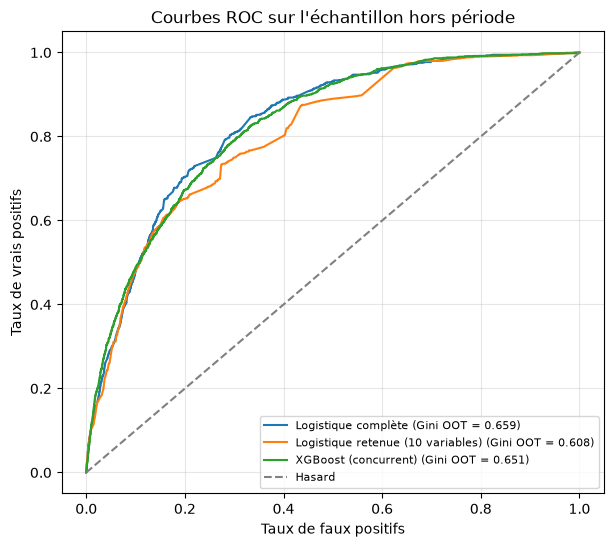

In [24]:
# Courbes ROC sur l'OOT
fig, ax = plt.subplots(figsize=(7, 6))
for nom, p_oot in predictions_oot.items():
    fpr, tpr, _ = roc_curve(y_oot, p_oot)
    ax.plot(fpr, tpr, label=f"{nom} (Gini OOT = {metriques(y_oot, p_oot)['Gini']:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Hasard")
ax.set_xlabel("Taux de faux positifs")
ax.set_ylabel("Taux de vrais positifs")
ax.set_title("Courbes ROC sur l'échantillon hors période")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.show()

### AUC PR et prévalence

Le Gini (ou l'AUC ROC) ne dépend pas de la part de défauts. Or, dans un segment où les défauts sont rares, un modèle peut avoir un bon Gini tout en produisant beaucoup de faux positifs parmi les clients jugés les plus risqués. L'**AUC PR** (aire sous la courbe précision-rappel, calculée ici par la précision moyenne) mesure directement cela.

Sa valeur dépend de la **prévalence** (taux de défaut de l'échantillon) : un modèle tiré au hasard a une AUC PR égale à la prévalence. Pour comparer le train, le test et l'OOT, qui n'ont pas forcément le même taux de défaut, nous regardons donc aussi le **rapport AUC PR / prévalence** (gain par rapport au hasard).

In [ ]:
from sklearn.metrics import average_precision_score, precision_recall_curve

# Prévalence (taux de défaut) de chaque échantillon
prevalences = {"train": y_train.mean(), "test": y_test.mean(), "oot": y_oot.mean()}
display(pl.DataFrame([
    {"echantillon": nom, "n": len(y), "n_defauts": int(y.sum()), "prevalence": y.mean()}
    for nom, y in (("train", y_train), ("test", y_test), ("oot", y_oot))
]))

# AUC PR (précision moyenne) par modèle et par échantillon, et gain par rapport au hasard
lignes = []
for nom, p_oot in predictions_oot.items():
    p_train, p_test = predictions[nom]
    ligne = {"modele": nom}
    for ech, y, p in (("train", y_train, p_train), ("test", y_test, p_test), ("oot", y_oot, p_oot)):
        auc_pr = average_precision_score(y, p)
        ligne[f"auc_pr_{ech}"] = auc_pr
        ligne[f"gain_{ech}"] = auc_pr / prevalences[ech]
    lignes.append(ligne)
performance_pr_oot = pl.DataFrame(lignes)
display(performance_pr_oot)

# Courbes précision-rappel sur l'OOT
fig, ax = plt.subplots(figsize=(7, 6))
for nom, p_oot in predictions_oot.items():
    precision, rappel, _ = precision_recall_curve(y_oot, p_oot)
    ax.plot(rappel, precision, label=f"{nom} (AUC PR OOT = {average_precision_score(y_oot, p_oot):.3f})")
ax.axhline(prevalences["oot"], linestyle="--", color="grey",
           label=f"Hasard (prévalence = {prevalences['oot']:.3%})")
ax.set_xlabel("Rappel (part des défauts détectés)")
ax.set_ylabel("Précision (part de défauts parmi les clients signalés)")
ax.set_title("Courbes précision-rappel sur l'échantillon hors période")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.show()

In [25]:
# Gini mois par mois sur l'OOT
lignes = []
for (mois,), d in sorted(oot.with_row_index("ligne").group_by(DATE_COL), key=lambda x: x[0]):
    idx = d["ligne"].to_numpy()
    y_m = y_oot[idx]
    ligne = {"mois": str(mois), "n": len(idx), "n_defauts": int(y_m.sum())}
    for nom, p_oot in predictions_oot.items():
        ligne[nom] = metriques(y_m, p_oot[idx])["Gini"] if 0 < y_m.sum() < len(y_m) else np.nan
    lignes.append(ligne)
display(pl.DataFrame(lignes))

mois,n,n_defauts,Logistique complète,Logistique retenue (10 variables),XGBoost (concurrent)
str,i64,i64,f64,f64,f64
"""2024-12-01""",165921,1099,0.659242,0.607829,0.651068


### Grille de score et distribution du score

La grille en points (PDO) est appliquée telle quelle. Nous vérifions que son Gini sur l'OOT est le même que celui du modèle, puis nous comparons la **distribution des scores** du train et de l'OOT. Le PSI du score est calculé sur les déciles du score du train.

methode,gini_train,gini_test,gini_oot
str,f64,f64,f64
"""PDO""",0.717466,0.664711,0.608519
"""Normalisation""",0.718393,0.66573,0.60867


PSI du score (OOT contre train) : 0.0516


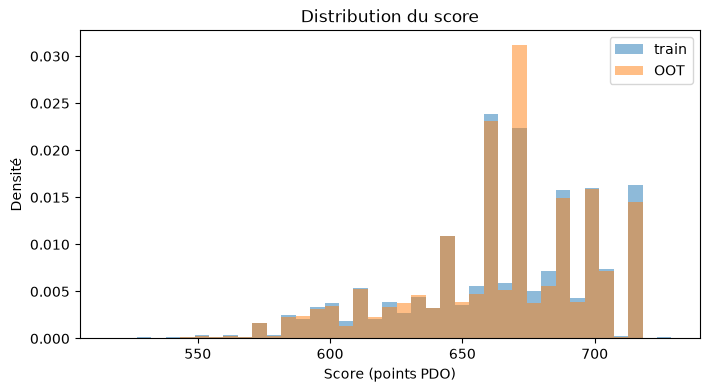

In [26]:
score_oot = score_grille(oot, "points_pdo")

lignes = []
for nom, colonne in (("PDO", "points_pdo"), ("Normalisation", "points_normalises")):
    lignes.append({
        "methode": nom,
        "gini_train": metriques(y_train, -score_grille(train, colonne))["Gini"],
        "gini_test": metriques(y_test, -score_grille(test, colonne))["Gini"],
        "gini_oot": metriques(y_oot, -score_grille(oot, colonne))["Gini"],
    })
display(pl.DataFrame(lignes))

# PSI du score, sur les déciles du score du train
bornes_deciles = np.unique(np.quantile(score_train, np.linspace(0.1, 0.9, 9)))
def parts_deciles(s):
    return np.bincount(np.searchsorted(bornes_deciles, s, side="right"), minlength=len(bornes_deciles) + 1) / len(s)

psi_score_oot = psi(parts_deciles(score_train), parts_deciles(score_oot))
print(f"PSI du score (OOT contre train) : {psi_score_oot:.4f}")

fig, ax = plt.subplots(figsize=(8, 4))
bins = np.linspace(min(score_train.min(), score_oot.min()), max(score_train.max(), score_oot.max()), 40)
ax.hist(score_train, bins=bins, density=True, alpha=0.5, label="train")
ax.hist(score_oot, bins=bins, density=True, alpha=0.5, label="OOT")
ax.set_xlabel("Score (points PDO)")
ax.set_ylabel("Densité")
ax.set_title("Distribution du score")
ax.legend()
plt.show()

**Lecture :** à compléter. Quel est le Gini OOT du modèle retenu, et son intervalle de confiance ? La baisse par rapport au test dépasse-t-elle 10 % ? L'écart avec XGBoost reste-t-il du même ordre qu'au développement ? Le score s'est-il déplacé (PSI) ?

## 7. Classes homogènes de risque sur l'OOT

Les bornes des CHR sont celles du train. Nous vérifions sur l'OOT les règles du cours (§7.2 à §7.6) :

- le taux de défaut augmente de la CHR 1 à la dernière ;
- les classes ont des tailles proches de celles du train (PSI) ;
- deux classes voisines ont des taux de défaut significativement différents ;
- le passage du score aux classes ne fait pas perdre trop de Gini.

In [27]:
oot_s = oot.with_columns(pl.Series(SCORE, score_oot),
                         pl.Series("PD_LR", predictions_oot["Logistique retenue (10 variables)"]))
oot_s = ajouter_chr(oot_s)

comparatif_chr = pl.DataFrame({"CHR": ORDRE_CHR})
for nom, df in (("train", train_s), ("test", test_s), ("oot", oot_s)):
    comparatif_chr = comparatif_chr.join(
        table_chr(df).select("CHR", pl.col("part_population").alias(f"part_{nom}"),
                             pl.col("n_defaut").alias(f"defauts_{nom}"),
                             pl.col("taux_defaut").alias(f"taux_{nom}")),
        on="CHR", how="left")
display(comparatif_chr)

taux_chr_oot = comparatif_chr["taux_oot"].to_numpy()
CHR_CROISSANTES_OOT = bool(np.all(np.diff(taux_chr_oot[~np.isnan(taux_chr_oot)]) >= 0))
print("Le taux de défaut augmente-t-il de la CHR 1 à la dernière sur l'OOT ?", CHR_CROISSANTES_OOT)
print("Même ordre des CHR qu'au train ?",
      bn.meme_ordre(bn.table_regle(train_s, SCORE, TARGET, regle_chr), bn.table_regle(oot_s, SCORE, TARGET, regle_chr)))

CHR,part_train,defauts_train,taux_train,part_test,defauts_test,taux_test,part_oot,defauts_oot,taux_oot
str,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""CHR 1""",0.586709,32.0,0.000873,0.593836,12.0,0.001292,0.620693,228.0,0.002214
"""CHR 2""",0.211607,49.0,0.003706,0.209604,13.0,0.003966,0.179176,157.0,0.005281
"""CHR 3""",0.150835,127.0,0.013476,0.146045,31.0,0.013573,0.151837,428.0,0.016989
"""CHR 4""",0.050849,151.0,0.047529,0.050515,34.0,0.043038,0.048294,286.0,0.035692


Le taux de défaut augmente-t-il de la CHR 1 à la dernière sur l'OOT ? True
Même ordre des CHR qu'au train ? True


Stabilité mois par mois (OOT) :


classe,taux_2024-12-01,ecart_min_suivante
str,f64,f64
"""]-inf ; 596]""",0.035692,1.100908
"""]596 ; 637]""",0.016989,2.216952
"""]637 ; 659]""",0.005281,1.385408
"""]659 ; +inf]""",0.002214,NaN


periode,psi_vs_train
str,f64
"""OOT (global)""",0.007447
"""2024-12-01""",0.007447


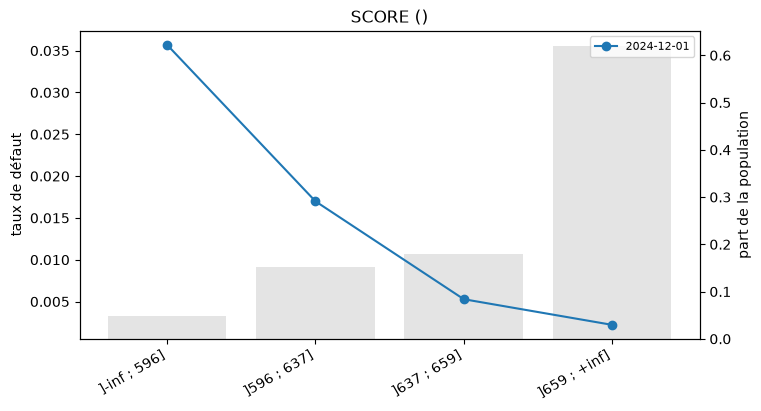

In [28]:
print("Stabilité mois par mois (OOT) :")
display(bn.stabilite_regle(oot_s, SCORE, TARGET, DATE_COL, regle_chr))

reference = repartition(train_s)
lignes = [{"periode": "OOT (global)", "psi_vs_train": psi(reference, repartition(oot_s))}]
for (mois,), d in sorted(oot_s.group_by(DATE_COL), key=lambda x: x[0]):
    lignes.append({"periode": str(mois), "psi_vs_train": psi(reference, repartition(d))})
psi_chr_oot = pl.DataFrame(lignes)
display(psi_chr_oot)

bn.graphique_regle(oot_s, SCORE, TARGET, DATE_COL, regle_chr)
plt.show()

In [29]:
print("Tests entre CHR voisines (OOT)")
display(tests_adjacents(oot_s))

# Homogénéité à l'intérieur des CHR, avec la même variable exogène qu'au développement
if VAR_EXOGENE in oot_s.columns:
    tranche = pl.when(pl.col(VAR_EXOGENE) <= 48).then(pl.lit("48 mois ou moins")).otherwise(pl.lit("plus de 48 mois"))
    display(
        oot_s.with_columns(tranche=tranche)
        .group_by("CHR", "tranche")
        .agg(n=pl.len(), taux=pl.col(TARGET).mean())
        .pivot(on="tranche", index="CHR", values=["n", "taux"])
        .sort(pl.col("CHR").str.extract(r"(\d+)").cast(pl.Int64))
    )

# Information perdue en passant du score aux classes
score_chr_oot = oot_s["CHR"].replace_strict(taux_par_chr, return_dtype=pl.Float64).to_numpy()
gini_score_oot = metriques(y_oot, -oot_s[SCORE].to_numpy())["Gini"]
gini_chr_oot = metriques(y_oot, score_chr_oot)["Gini"]
print(f"OOT : Gini du score = {gini_score_oot:.4f} | Gini des CHR = {gini_chr_oot:.4f} "
      f"| perte = {gini_score_oot - gini_chr_oot:.4f}")

Tests entre CHR voisines (OOT)


paire,taux_1,taux_2,p_value
str,f64,f64,f64
"""CHR 1 / CHR 2""",0.002214,0.005281,7.9224e-18
"""CHR 2 / CHR 3""",0.005281,0.016989,3.1592e-40
"""CHR 3 / CHR 4""",0.016989,0.035692,1.3855e-23


CHR,n_plus de 48 mois,n_48 mois ou moins,taux_plus de 48 mois,taux_48 mois ou moins
str,u32,u32,f64,f64
"""CHR 1""",96291,6695,0.002306,0.000896
"""CHR 2""",22584,7145,0.005535,0.004479
"""CHR 3""",16992,8201,0.017126,0.016705
"""CHR 4""",3288,4725,0.047141,0.027725


OOT : Gini du score = 0.6085 | Gini des CHR = 0.5252 | perte = 0.0833


**Lecture :** à compléter. Les CHR restent-elles ordonnées sur l'OOT ? Leurs tailles ont-elles bougé (PSI) ? Des classes voisines deviennent-elles indistinctes ? Si c'est le cas, faut-il les regrouper ?

## 8. Calibrage sur l'OOT

Nous comparons le taux de défaut observé sur l'OOT à deux probabilités de défaut fixées au développement :

- la **PD LRA** de chaque CHR (moyenne de long terme, §8.4) ;
- la **PD réglementaire**, qui ajoute les marges de prudence (MoC) et le plancher (§8.7).

Deux tests par CHR, qui cherchent tous les deux une **sous-estimation** du risque :

- le **test binomial** : probabilité d'observer au moins autant de défauts si la PD était juste ;
- le **test de Jeffreys** (utilisé par la BCE) : même question, avec une loi Beta(d + ½, n − d + ½) pour le taux observé.

Une p-value inférieure à 5 % signale une PD trop basse pour cette classe. Rappel : le taux observé sur une période courte est un taux **PIT**, alors que la PD LRA est une moyenne de long terme. Un écart peut donc venir de la conjoncture, et pas du modèle.

In [30]:
pd_regl = dict(zip(pd_reglementaire["CHR"].to_list(), pd_reglementaire["pd_reglementaire"].to_list()))

verif_oot = (
    table_chr(oot_s)
    .select("CHR", "n", "n_defaut", "taux_defaut")
    .with_columns(
        pd_lra=pl.col("CHR").replace_strict(pd_lra, return_dtype=pl.Float64),
        pd_reglementaire=pl.col("CHR").replace_strict(pd_regl, return_dtype=pl.Float64),
    )
)


def p_binomial(d, n, p):
    return float(stats.binom.sf(d - 1, n, p))


def p_jeffreys(d, n, p):
    return float(stats.beta.cdf(p, d + 0.5, n - d + 0.5))


lignes = verif_oot.select("n_defaut", "n", "pd_lra", "pd_reglementaire").iter_rows()
p_tests = [(p_binomial(d, n, p1), p_jeffreys(d, n, p1), p_binomial(d, n, p2)) for d, n, p1, p2 in lignes]
verif_oot = verif_oot.with_columns(
    p_binomial_lra=pl.Series([t[0] for t in p_tests]),
    p_jeffreys_lra=pl.Series([t[1] for t in p_tests]),
    p_binomial_reglementaire=pl.Series([t[2] for t in p_tests]),
)
display(verif_oot)

CHR_SOUS_ESTIMEES = verif_oot.filter(pl.col("p_binomial_lra") < ALPHA_OOT)["CHR"].to_list()
print("CHR dont la PD LRA est sous-estimée (binomial, 5 %) :", CHR_SOUS_ESTIMEES or "aucune")
print("CHR dont la PD réglementaire est sous-estimée :",
      verif_oot.filter(pl.col("p_binomial_reglementaire") < ALPHA_OOT)["CHR"].to_list() or "aucune")

CHR,n,n_defaut,taux_defaut,pd_lra,pd_reglementaire,p_binomial_lra,p_jeffreys_lra,p_binomial_reglementaire
str,u32,f64,f64,f64,f64,f64,f64,f64
"""CHR 1""",102986,228.0,0.002214,0.000872,0.001089,2.1007e-34,1.3132e-34,5.6800e-22
"""CHR 2""",29729,157.0,0.005281,0.003704,0.004436,0.000015,0.000012,0.017831
"""CHR 3""",25193,428.0,0.016989,0.013467,0.015064,0.000002,0.000002,0.007303
"""CHR 4""",8013,286.0,0.035692,0.045996,0.051039,0.999998,0.999998,1.0


CHR dont la PD LRA est sous-estimée (binomial, 5 %) : ['CHR 1', 'CHR 2', 'CHR 3']
CHR dont la PD réglementaire est sous-estimée : ['CHR 1', 'CHR 2', 'CHR 3']


In [31]:
# Niveau global : PD moyenne prévue contre taux de défaut observé
pd_oot = oot_s["CHR"].replace_strict(pd_lra, return_dtype=pl.Float64).to_numpy()
pd_regl_oot = oot_s["CHR"].replace_strict(pd_regl, return_dtype=pl.Float64).to_numpy()
d_oot, n_oot = int(y_oot.sum()), len(y_oot)
print(f"Taux observé : {y_oot.mean():.4%} | PD LRA moyenne : {pd_oot.mean():.4%} "
      f"| PD réglementaire moyenne : {pd_regl_oot.mean():.4%}")
print(f"Test binomial global (PD LRA) : p-value = {p_binomial(d_oot, n_oot, pd_oot.mean()):.4f}")

# Mois par mois
display(
    oot_s.with_columns(pd_lra=pl.Series(pd_oot))
    .group_by(DATE_COL).agg(n=pl.len(), taux_observe=pl.col(TARGET).mean(), pd_lra_moyenne=pl.col("pd_lra").mean())
    .sort(DATE_COL)
)

Taux observé : 0.6624% | PD LRA moyenne : 0.5471% | PD réglementaire moyenne : 0.6223%
Test binomial global (PD LRA) : p-value = 0.0000


datdelhis,n,taux_observe,pd_lra_moyenne
date,u32,f64,f64
2024-12-01,165921,0.006624,0.005471


Brier OOT = 0.006519 (test : 0.005631)
Fiabilité = 8.58e-06 | Résolution = 6.95e-05 | Incertitude = 6.58e-03


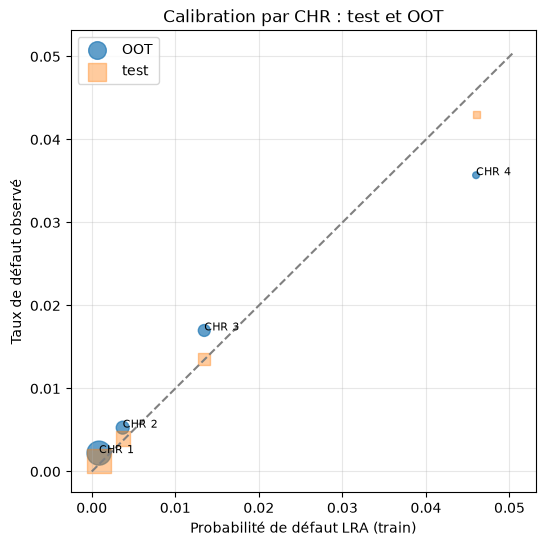

In [32]:
# Score de Brier et décomposition de Murphy sur l'OOT (avec la PD LRA)
taux_moyen_oot = y_oot.mean()
brier_oot = np.mean((pd_oot - y_oot) ** 2)
fiabilite_oot = float((verif_oot["n"] * (verif_oot["pd_lra"] - verif_oot["taux_defaut"]) ** 2).sum() / n_oot)
resolution_oot = float((verif_oot["n"] * (verif_oot["taux_defaut"] - taux_moyen_oot) ** 2).sum() / n_oot)
incertitude_oot = taux_moyen_oot * (1 - taux_moyen_oot)

print(f"Brier OOT = {brier_oot:.6f} (test : {brier:.6f})")
print(f"Fiabilité = {fiabilite_oot:.2e} | Résolution = {resolution_oot:.2e} | Incertitude = {incertitude_oot:.2e}")

# Graphique de calibration
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(verif_oot["pd_lra"], verif_oot["taux_defaut"], s=verif_oot["n"] / verif_oot["n"].max() * 300,
           alpha=0.7, label="OOT")
ax.scatter(verif["pd_lra"], verif["taux_defaut"], s=verif["n"] / verif["n"].max() * 300,
           alpha=0.4, marker="s", label="test")
for nom_chr, x, y in verif_oot.select("CHR", "pd_lra", "taux_defaut").iter_rows():
    ax.annotate(nom_chr, (x, y), fontsize=8)
borne = max(verif_oot["pd_lra"].max(), verif_oot["taux_defaut"].max(), verif["taux_defaut"].max()) * 1.1
ax.plot([0, borne], [0, borne], linestyle="--", color="grey")
ax.set_xlabel("Probabilité de défaut LRA (train)")
ax.set_ylabel("Taux de défaut observé")
ax.set_title("Calibration par CHR : test et OOT")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

**Lecture :** à compléter. Des CHR sont-elles sous-estimées ? La PD réglementaire, avec ses marges, couvre-t-elle le taux observé ? Si l'écart est le même dans toutes les classes, c'est plutôt un **effet de niveau** (conjoncture), à traiter par le calibrage ; si l'écart touche une seule classe, c'est plutôt un problème d'**ordonnancement**.

## 9. Synthèse et décision

Le tableau reprend les indicateurs principaux avec leur statut. Il est enregistré, avec les tables détaillées, dans un fichier Excel pour le dossier de validation.

In [33]:
def statut_psi(x):
    return "stable" if x < PSI_SURVEILLANCE else ("à surveiller" if x < PSI_ALERTE else "alerte")


def statut_baisse(x):
    return "stable" if x < BAISSE_GINI_SURVEILLANCE else ("à surveiller" if x < BAISSE_GINI_ALERTE else "alerte")


retenu = performance_oot.filter(pl.col("modele") == "Logistique retenue (10 variables)").row(0, named=True)
xgb = performance_oot.filter(pl.col("modele") == "XGBoost (concurrent)").row(0, named=True)
psi_chr_global = psi_chr_oot["psi_vs_train"][0]
variables_retenues = stabilite_variables.filter(pl.col("dans_modele_retenu"))
csi_max = variables_retenues["csi_oot"].max()

synthese_oot = pl.DataFrame([
    {"indicateur": "Gini OOT du modèle retenu",
     "valeur": f"{retenu['gini_oot']:.3f} [{retenu['ic95_bas']:.3f} ; {retenu['ic95_haut']:.3f}]",
     "reference": f"test : {retenu['gini_test']:.3f}", "statut": statut_baisse(retenu["baisse_relative_vs_test"])},
    {"indicateur": "Baisse relative du Gini (OOT / test)", "valeur": f"{retenu['baisse_relative_vs_test']:.1%}",
     "reference": f"< {BAISSE_GINI_SURVEILLANCE:.0%}", "statut": statut_baisse(retenu["baisse_relative_vs_test"])},
    {"indicateur": "Écart de Gini XGBoost − logistique (OOT)", "valeur": f"{xgb['gini_oot'] - retenu['gini_oot']:.3f}",
     "reference": f"test : {xgb['gini_test'] - retenu['gini_test']:.3f}", "statut": "information"},
    {"indicateur": "PSI du score", "valeur": f"{psi_score_oot:.3f}",
     "reference": f"< {PSI_SURVEILLANCE}", "statut": statut_psi(psi_score_oot)},
    {"indicateur": "PSI des CHR", "valeur": f"{psi_chr_global:.3f}",
     "reference": f"< {PSI_SURVEILLANCE}", "statut": statut_psi(psi_chr_global)},
    {"indicateur": "CSI maximal des variables du modèle", "valeur": f"{csi_max:.3f}",
     "reference": f"< {PSI_SURVEILLANCE}", "statut": statut_psi(csi_max)},
    {"indicateur": "Variables du modèle dont l'ordre des classes change",
     "valeur": str(variables_retenues.filter(~pl.col("meme_ordre_que_train")).height),
     "reference": "0", "statut": "stable" if variables_retenues["meme_ordre_que_train"].all() else "à surveiller"},
    {"indicateur": "CHR ordonnées sur l'OOT", "valeur": str(CHR_CROISSANTES_OOT),
     "reference": "True", "statut": "stable" if CHR_CROISSANTES_OOT else "alerte"},
    {"indicateur": "CHR dont la PD LRA est sous-estimée", "valeur": str(len(CHR_SOUS_ESTIMEES)),
     "reference": "0", "statut": "stable" if not CHR_SOUS_ESTIMEES else "alerte"},
])
display(synthese_oot)

indicateur,valeur,reference,statut
str,str,str,str
"""Gini OOT du modèle retenu""","""0.608 [0.586 ; 0.630]""","""test : 0.666""","""stable"""
"""Baisse relative du Gini (OOT /…","""8.8%""","""< 10%""","""stable"""
"""Écart de Gini XGBoost − logist…","""0.043""","""test : 0.045""","""information"""
"""PSI du score""","""0.052""","""< 0.1""","""stable"""
"""PSI des CHR""","""0.007""","""< 0.1""","""stable"""
"""CSI maximal des variables du m…","""1.230""","""< 0.1""","""alerte"""
"""Variables du modèle dont l'ord…","""0""","""0""","""stable"""
"""CHR ordonnées sur l'OOT""","""True""","""True""","""stable"""
"""CHR dont la PD LRA est sous-es…","""3""","""0""","""alerte"""


In [34]:
ex.exporter_excel({
    "0_Synthese": synthese_oot,
    "1_Perimetre_OOT": suivi_perimetre_oot,
    "4_Cible_par_mois": pl.concat([defaut_par_mois(base_dev, "développement"), defaut_mois_oot]),
    "5_Manquants": manquants,
    "5_Valeurs_nouvelles": valeurs_nouvelles,
    "5_Stabilite_variables": stabilite_variables,
    "6_Performance": performance_oot,
    "7_CHR": comparatif_chr,
    "7_PSI_CHR": psi_chr_oot,
    "8_Calibrage": verif_oot,
}, SORTIES_OOT / "validation_oot.xlsx")
print("Export :", SORTIES_OOT / "validation_oot.xlsx")

Export : outputs\scorecard\SA_mono_sans_engagement\oot\validation_oot.xlsx


**Conclusion :** à compléter. Trois issues possibles :

1. **Le score est validé** : Gini proche du test, populations stables, CHR ordonnées et PD non sous-estimées.
2. **Le score est validé avec réserves** : l'ordonnancement tient, mais le niveau de risque a bougé. On garde la grille et on revoit le calibrage (LRA, marges de prudence).
3. **Le score doit être revu** : le Gini baisse nettement, ou les CHR ne sont plus ordonnées. Il faut identifier les variables en cause (partie 5) avant de reconstruire le modèle.

### Journal des décisions (OOT)

| Point | Constat | Décision |
|---|---|---|
| Périmètre et segment | à compléter | |
| Stabilité des variables | à compléter | |
| Pouvoir discriminant | à compléter | |
| CHR | à compléter | |
| Calibrage | à compléter | |